# Data Preprocessing: Market Basket Analysis Dataset (XLSX)
Notebook ini memuat tahap pra-pemrosesan data (*Data Understanding & Preprocessing*) untuk dataset keranjang belanja (*Market Basket Analysis*).

* **Dataset Asal:** `market basket analysist.xlsx` (diekspor ke `market_basket_analysist.csv`)
* **Karakteristik Data:** 1.863 transaksi dengan distribusi item belanja horizontal (`item1` s.d `item7`).
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Jumlah Record & Atribut)
  2. Analisis Nilai Kosong (*Missing Value*) & Visualisasi Heatmap
  3. Pemeriksaan Data Duplikat & Transaksi Unik
  4. Analisis Frekuensi Produk Terpopuler
  5. Deteksi Data Pencilan (*Outlier*) pada Ukuran Keranjang Belanja menggunakan Metode IQR dan Boxplot


### 1. Import Library
Memanggil library data science (pandas, numpy, matplotlib, seaborn).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### 2. Membaca Dataset
Memuat file CSV dataset transaksi keranjang belanja ke dalam DataFrame pandas.


In [2]:
df = pd.read_csv('market_basket_analysist.csv')


### 3. Menampilkan 5 Data Teratas (Head)
Melihat sampel 5 baris pertama data transaksi belanja.


In [3]:
df.head()


,itemset,item1,item2,item3,item4,item5,item6,item7
0,1,baking powder,coffee,frozen meals,butter,NaN,NaN,NaN
1,2,ice cream,abrasive cleaner,fish,coffee,frozen meals,NaN,NaN
2,3,butter,baking powder,coffee,ice cream,frozen meals,NaN,NaN
3,4,frozen vegetables,abrasive cleaner,ice cream,butter,coffee,NaN,NaN
4,5,baking powder,ice cream,butter,frozen meals,NaN,NaN,NaN


### 4. Menampilkan 5 Data Terbawah (Tail)
Melihat sampel 5 baris terakhir data transaksi belanja.


In [4]:
df.tail()


,itemset,item1,item2,item3,item4,item5,item6,item7
1858,1859,grapes,frozen vegetables,baking powder,frozen meals,butter,NaN,NaN
1859,1860,frozen vegetables,butter,coffee,abrasive cleaner,ice cream,fish,NaN
1860,1861,frozen vegetables,coffee,fish,grapes,frozen meals,NaN,NaN
1861,1862,fish,frozen meals,butter,ice cream,NaN,NaN,NaN
1862,1863,baking powder,coffee,butter,grapes,cake bar,frozen meals,NaN


### 5. Jumlah Baris (Record)
Menghitung total baris transaksi pada dataset.


In [5]:
print("Jumlah Baris:", len(df))


Jumlah Baris: 1863


### 6. Jumlah Kolom (Atribut)
Menghitung total kolom pada dataset.


In [6]:
print("Jumlah Kolom:", len(df.columns))


Jumlah Kolom: 8


### 7. Cek Tipe Data & Struktur DataFrame
Memeriksa informasi tipe data setiap kolom dan ringkasan penggunaan memori.


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1863 entries, 0 to 1862
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   itemset  1863 non-null   int64
 1   item1    1849 non-null   str  
 2   item2    1639 non-null   str  
 3   item3    1383 non-null   str  
 4   item4    1023 non-null   str  
 5   item5    602 non-null    str  
 6   item6    211 non-null    str  
 7   item7    38 non-null     str  
dtypes: int64(1), str(7)
memory usage: 116.6 KB


### 8. Cek Missing Value per Kolom
Menghitung jumlah nilai kosong (NaN/null) pada masing-masing kolom transaksi.


In [8]:
df.isnull().sum().to_frame(name='Jumlah Missing Value')


,Jumlah Missing Value
itemset,0
item1,14
item2,224
item3,480
item4,840
item5,1261
item6,1652
item7,1825


### 9. Total Missing Value Keseluruhan
Menghitung total seluruh nilai kosong pada dataset.


In [9]:
print("Total Missing Value Keseluruhan:", df.isnull().sum().sum())


Total Missing Value Keseluruhan: 6296


### 10. Persentase Missing Value
Menghitung rasio persentase data kosong terhadap total sel data.


In [10]:
total_sel = len(df) * len(df.columns)
persen_missing = (df.isnull().sum().sum() / total_sel) * 100
print(f"Persentase Missing Value: {persen_missing:.2f}%")


Persentase Missing Value: 42.24%


### 11. Visualisasi Heatmap Missing Value
Menampilkan peta sebaran nilai kosong pada seluruh transaksi.


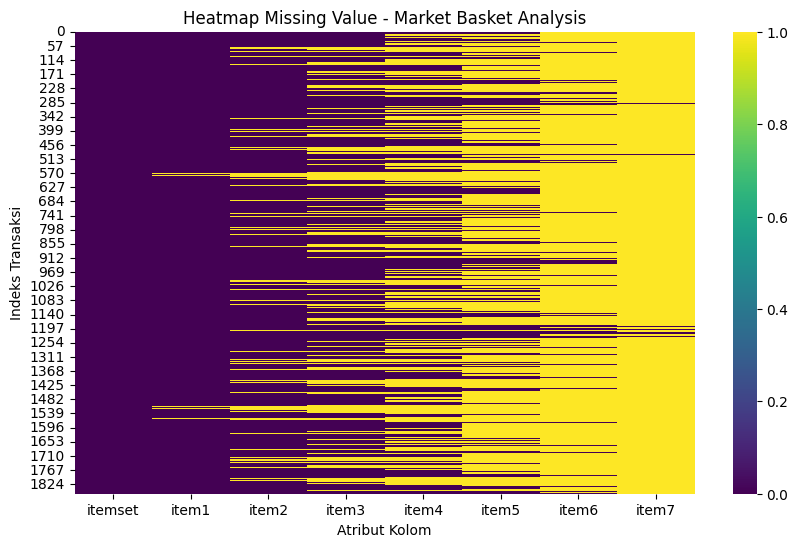

In [11]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value - Market Basket Analysis')
plt.xlabel('Atribut Kolom')
plt.ylabel('Indeks Transaksi')
plt.show()


### 12. Cek Jumlah Duplikat Transaksi
Memeriksa baris belanja dengan kombinasi item yang identik.


In [12]:
item_cols = [c for c in df.columns if c != 'itemset']
jumlah_duplikat = df.drop(columns=['itemset']).duplicated().sum()
print("Jumlah Transaksi Duplikat:", jumlah_duplikat)


Jumlah Transaksi Duplikat: 1500


### 13. Cek Jumlah Transaksi Unik
Menghitung total identifier transaksi unik (itemset).


In [13]:
print("Jumlah Transaksi Unik:", df['itemset'].nunique())


Jumlah Transaksi Unik: 1863


### 14. Frekuensi Produk Terpopuler
Menghitung frekuensi kemunculan setiap produk di seluruh keranjang belanja.


In [14]:
item_cols = [c for c in df.columns if c != 'itemset']
all_items = pd.Series(df[item_cols].values.flatten()).dropna().str.strip()
all_items = all_items[all_items != '']
top_items = all_items.value_counts().to_frame(name='Jumlah Pembelian')
display(top_items)


,Jumlah Pembelian
frozen meals,1002
butter,840
baking powder,663
coffee,606
fish,563
ice cream,554
frozen vegetables,541
grapes,445
domestic eggs,430
cake bar,386


### 15. Hitung Ukuran Keranjang Belanja per Transaksi
Menghitung banyaknya produk yang dibeli pada setiap nomor transaksi.


In [15]:
item_cols = [c for c in df.columns if c != 'itemset']
item_per_transaksi = df[item_cols].notna().sum(axis=1)
item_per_transaksi.name = 'Ukuran_Keranjang' 


### 16. Statistik Deskriptif Ukuran Keranjang Belanja
Melihat nilai rata-rata, standar deviasi, nilai minimum, dan maksimum ukuran keranjang.


In [16]:
item_per_transaksi.describe().to_frame(name='Statistik Deskriptif')


,Statistik Deskriptif
count,1863.000000
mean,3.620505
std,1.581087
min,0.000000
25%,2.000000
50%,4.000000
75%,5.000000
max,7.000000


### 17. Visualisasi Boxplot Ukuran Keranjang Belanja
Menampilkan diagram kotak garis (Boxplot) untuk menganalisis sebaran dan potensi pencilan.


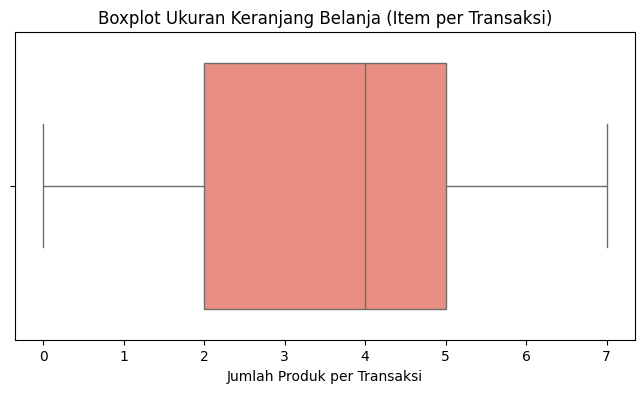

In [17]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=item_per_transaksi, color='salmon')
plt.title('Boxplot Ukuran Keranjang Belanja (Item per Transaksi)')
plt.xlabel('Jumlah Produk per Transaksi')
plt.show()


### 18. Perhitungan Kuartil (Q1, Q3) dan IQR
Menghitung batas kuartil bawah (25%), kuartil atas (75%), dan rentang antarkuartil (IQR).


In [18]:
Q1 = item_per_transaksi.quantile(0.25)
Q3 = item_per_transaksi.quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 (Kuartil Bawah) : {Q1}")
print(f"Q3 (Kuartil Atas)  : {Q3}")
print(f"IQR               : {IQR}")


Q1 (Kuartil Bawah) : 2.0
Q3 (Kuartil Atas)  : 5.0
IQR               : 3.0


### 19. Perhitungan Batas Atas Outlier
Menghitung ambang batas atas deteksi outlier menggunakan rumus Q3 + (1.5 * IQR).


In [19]:
batas_atas = Q3 + 1.5 * IQR
print("Batas Atas Outlier:", batas_atas)


Batas Atas Outlier: 9.5


### 20. Jumlah Transaksi Terdeteksi Outlier
Menghitung total transaksi belanja yang melampaui batas atas IQR.


In [20]:
outliers = item_per_transaksi[item_per_transaksi > batas_atas]
print("Jumlah Transaksi Outlier:", len(outliers))


Jumlah Transaksi Outlier: 0


### 21. Daftar Transaksi dengan Pembelian Terbanyak
Menampilkan 10 transaksi dengan volume produk tertinggi.


In [21]:
item_per_transaksi.sort_values(ascending=False).head(10).to_frame(name='Jumlah Item')


,Jumlah Item
528,7
512,7
64,7
104,7
80,7
500,7
495,7
524,7
1468,7
1452,7
